In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import torch
from diffusers import StableDiffusionPipeline, DDPMScheduler
from transformers import CLIPTokenizer
from dataset.mama_mia import get_dataloaders
import argparse
from diffusers import AutoencoderKL, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer

# Initialize args with default values
args = argparse.Namespace(
    model_name_or_path="runwayml/stable-diffusion-v1-5",
    data_dir="data/images",
    segmentation_dir="data/segmentations",
    split_file="data/train_test_splits.csv",
    patient_info_dir="data/patient_info_files",
    train_batch_size=6,
    num_workers=4,
    segmentation_type="expert",
    resolution=512,
    center_crop=True,
    verbose=False
)
# Initialize tokenizer and dataset
tokenizer = CLIPTokenizer.from_pretrained(args.model_name_or_path, subfolder="tokenizer")

train_loader, test_loader = get_dataloaders(
    data_dir=args.data_dir,
    segmentation_dir=args.segmentation_dir, 
    split_file=args.split_file,
    patient_info_dir=args.patient_info_dir,
    tokenizer=tokenizer,
    batch_size=args.train_batch_size,
    num_workers=args.num_workers,
    segmentation_type=args.segmentation_type,
    size=args.resolution,
    center_crop=args.center_crop,
    verbose=args.verbose
)

print(f"Train dataset size: {len(train_loader.dataset)}")
print(f"Test dataset size: {len(test_loader.dataset)}")


/home/luab/MRI-diffusion/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 707296 training samples
Found 179548 test samples
Train dataset size: 707296
Test dataset size: 179548


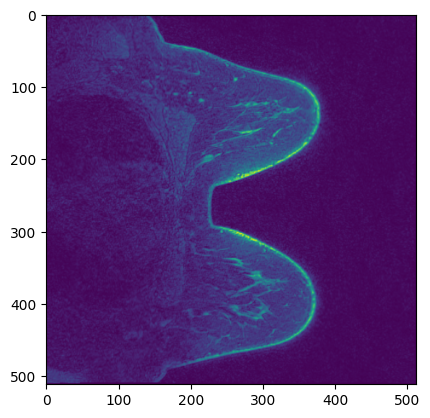

In [ ]:
from matplotlib import pyplot as plth
plt.imshow(train_loader.dataset[100]['image'].squeeze()[0])

In [9]:
train_loader.dataset[100]['image'].squeeze().max()

tensor(0.9373)

In [10]:
train_loader.dataset[100]['image'].squeeze().min()

tensor(-1.)

In [12]:
import nibabel as nib
nifti_img = nib.load("./data/images/DUKE_001/DUKE_001_0000.nii.gz")
nifti_img.get_fdata().shape


(448, 448, 160)